# Mass Alignment Calibration

*Author: [Andrew Causer](https://agc888.github.io/OspreyAI)*

This notebook demonstrates how to perform mass alignment calibration using *goatpy*.

For more infomation on how to run general analysis using *goatpy* please visit the [Getting Started](https://goatpy.readthedocs.io/en/latest/guides/getting_started.html#Loading-and-Aligning-Data) page.


In [1]:
import goatpy as gp

REFERENCE_MZ = [1257.4230, 1419.4750, 1581.5280, 1809.6390, 1905.6340]
    
gp.calibrate_imzml_file(
        input_path = "./Documents/kidney/kidney_rawdata.imzML",  
        reference_mz = REFERENCE_MZ,
        output_path = "./Documents/kidney/calibrated_data/calibrated_goatpy.imzML",  
        tolerance = 350.0,
        tolerance_unit = "ppm",
        method = "quadratic",
        save_qc_folder = "./Documents/kidney/calibrated_data/qc_results"
        )

Calibrating + writing: 100%|██████████| 86270/86270 [02:10<00:00, 661.57it/s]


Calibration complete: 
   reference_mz  observed_mz  n_pixels_found  error_da   error_ppm
0      1257.423  1257.772339             500  0.349339  277.821280
1      1419.475  1419.830811             500  0.355811  250.663483
2      1581.528  1581.889404             500  0.361404  228.515902
3      1809.639  1809.995728             500  0.356728  197.126355
4      1905.634  1906.006470             500  0.372470  195.457116


After running the calibration function we can see the saved files stored our specified folder:

```.
├── calibrated_goatpy.ibd
├── calibrated_goatpy.imzML
└── qc_results
    ├── calibration_qc_new_update.csv
    ├── coarse_prealign_diagnostics_new_update.csv
    └── qc_spatial.png  

```

Looking at the qc plots generated, the ppm differences between pixels is significantly reduced after running the calibration. 

<div align="center">
    <img src="../../_static/tutorial_images/qc_spatial.png" width="500">
</div>


After running calibration using *goatpy* lets visualise how the spectra has been adjusted. We will also compare this against the raw and mass corrected data using Bruker flex and SCiLS calibration.

In [3]:
"""
plot_mean_spectra.py

Compute and plot the mean spectrum (averaged across all pixels) for one or
more imzML files, restricted to a specified m/z window.

Designed for comparing multiple versions of the same dataset, e.g.:
    raw / goatpy-calibrated / bruker-flex-calibrated / bruker-scils-calibrated

Requires: pyimzml, numpy, matplotlib
    pip install pyimzml numpy matplotlib
"""

import numpy as np
import matplotlib.pyplot as plt
from pyimzml.ImzMLParser import ImzMLParser


def _get_mean_spectrum(imzml_path, mz_min, mz_max, n_points=2000):
    parser = ImzMLParser(imzml_path)
    n_pixels = len(parser.coordinates)

    is_continuous = "continuous" in parser.metadata.file_description.param_by_name

    mz_grid = np.linspace(mz_min, mz_max, n_points)
    intensity_sum = np.zeros(n_points, dtype=np.float64)
    n_used = 0

    for idx in range(n_pixels):
        mzs, intensities = parser.getspectrum(idx)

        mask = (mzs >= mz_min) & (mzs <= mz_max)
        if not np.any(mask):
            continue

        mzs_win = mzs[mask]
        intens_win = intensities[mask]

        if is_continuous and idx == 0:
            pass

        interp_intens = np.interp(
            mz_grid, mzs_win, intens_win, left=0.0, right=0.0
        )

        intensity_sum += interp_intens
        n_used += 1

    parser.close() if hasattr(parser, "close") else None

    if n_used == 0:
        raise ValueError(
            f"No spectra had data in the window [{mz_min}, {mz_max}] "
            f"for file: {imzml_path}"
        )

    mean_intensity = intensity_sum / n_used
    return mz_grid, mean_intensity, n_used


def plot_mean_spectra(
    imzml_files,
    mz_min,
    mz_max,
    labels=None,
    n_points=2000,
    normalize=False,
    figsize=(10, 6),
    save_path=None,
):
    if labels is None:
        labels = [f.split("/")[-1] for f in imzml_files]
    assert len(labels) == len(imzml_files), "labels must match imzml_files length"

    fig, ax = plt.subplots(figsize=figsize)
    results = {}

    for path, label in zip(imzml_files, labels):
        mz_grid, mean_intensity, n_used = _get_mean_spectrum(
            path, mz_min, mz_max, n_points=n_points
        )

        if normalize:
            peak = mean_intensity.max()
            if peak > 0:
                mean_intensity = mean_intensity / peak

        ax.plot(mz_grid, mean_intensity, label=f"{label} (n={n_used})", linewidth=1)
        results[label] = (mz_grid, mean_intensity, n_used)

    ax.set_xlabel("m/z")
    ax.set_ylabel("Mean intensity (normalized)" if normalize else "Mean intensity")
    ax.set_title(f"Mean spectrum across pixels, m/z {mz_min}\u2013{mz_max}")
    ax.set_xlim(mz_min, mz_max)
    ax.legend()
    fig.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=200)

    return fig, ax, results



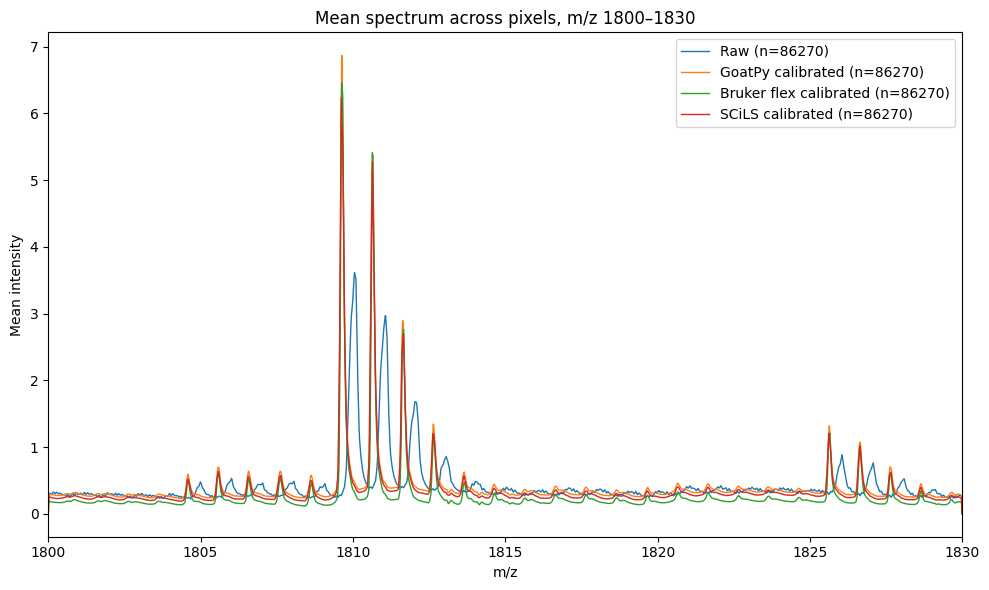

In [4]:
files = [
        "./Documents/kidney/kidney_rawdata.imzML",
         "./Documents/kidney/calibrated_data/calibrated_goatpy.imzML",
          "./Documents/kidney/calibrated_data/kidney_flex_recal.imzML",
           "./Documents/kidney/calibrated_data/kidney_scils_recal.imzML",
    ]

labels = ["Raw", "GoatPy calibrated", "Bruker flex calibrated", "SCiLS calibrated"]

fig, ax, results = plot_mean_spectra(
        files,
        mz_min=1800,
        mz_max=1830,
        labels=labels,
        normalize=False,
    )
plt.show()

Lets zoom into the peak at 1809.6

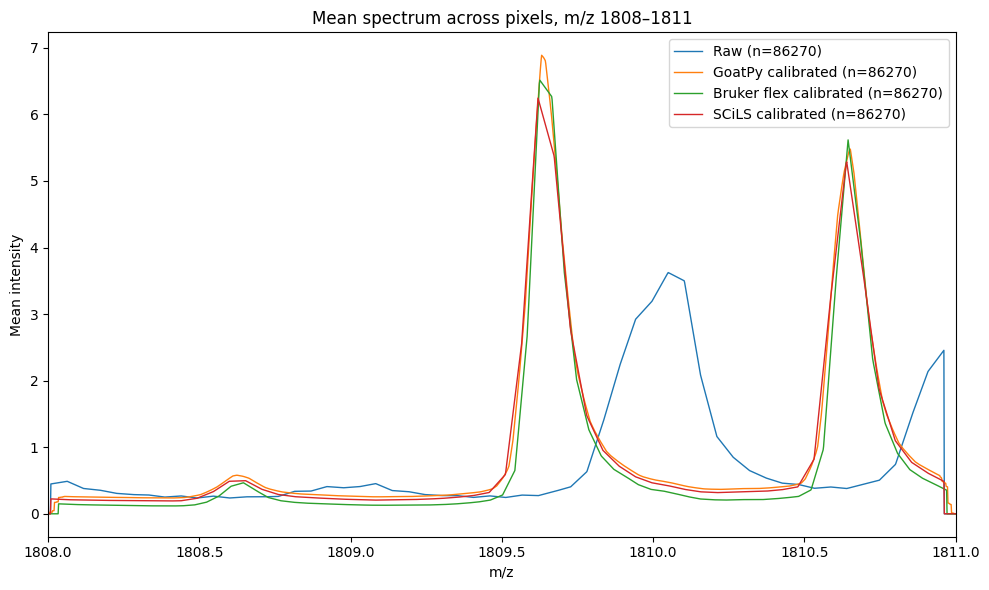

In [5]:
labels = ["Raw", "GoatPy calibrated", "Bruker flex calibrated", "SCiLS calibrated"]

fig, ax, results = plot_mean_spectra(
        files,
        mz_min=1808,
        mz_max=1811,
        labels=labels,
        normalize=False,
    )
plt.show()

Lets run a more robust benchmarking comparison comparing the relative error between the theoretical values compared to the adjusted mass values following calibration. 

We will us the following masses to test this:

`1257.4226`,`1419.4755`,`1809.6393`,`1905.6339`,`2012.7187` and `2215.798`

In [ ]:
"""
glycan_calibration_benchmark.py
================================

Benchmark multiple MALDI-MSI m/z calibration functions against one another
and/or a reference calibration, using the raw (uncalibrated) data as a
baseline.

Pipeline
--------
1. load_glycan_library()      -> load theoretical m/z reference table
2. filter_library_by_mz()     -> restrict to target glycans
3. extract_peaks_from_imzml() -> pull per-pixel observed m/z for each glycan
4. compute_ppm_errors()       -> attach theoretical m/z + ppm error columns
5. run_benchmark()            -> per-glycan and global statistics comparing
                                  ANY number of datasets
6. plot_* functions           -> diagnostic plots
7. run_full_report()          -> complete end-to-end benchmark

The benchmark now supports an arbitrary number of .imzML files.

Example:

    datasets = {
        "raw": "/path/raw.imzML",
        "mine": "/path/my_calibration.imzML",
        "reference": "/path/reference.imzML",
        "fourth": "/path/fourth_calibration.imzML",
    }

All pairwise comparisons are automatically performed.

Dependencies
------------
pandas
numpy
scipy
matplotlib
seaborn
pyimzml
joblib

Install:
    pip install pyimzml joblib --break-system-packages
"""

from __future__ import annotations

import os
import warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd

from scipy import stats

from joblib import Parallel, delayed
from functools import partial

import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(
    style="whitegrid",
    context="talk",
)

def load_glycan_library(
    csv_path: str,
    mz_col: str = "Theoretical_m/z",
    id_col: str = "Composition",
) -> pd.DataFrame:

    lib = pd.read_csv(csv_path)

    lib = lib.rename(
        columns={
            mz_col: "theoretical_mz",
            id_col: "glycan_id",
        }
    )

    if lib["glycan_id"].duplicated().any():

        dupes = (
            lib.loc[
                lib["glycan_id"].duplicated(),
                "glycan_id"
            ]
            .unique()
        )

        warnings.warn(
            f"{len(dupes)} duplicate glycan_id values in library "
            f"(e.g. {dupes[:5]}); keeping first occurrence of each."
        )

        lib = lib.drop_duplicates(
            subset="glycan_id",
            keep="first",
        )

    lib = lib.set_index(
        "glycan_id",
        drop=False,
    )

    return lib


def filter_library_by_mz(
    library: pd.DataFrame,
    target_mz: list,
    tolerance_ppm: float = 50.0,
) -> pd.DataFrame:

    rows = []

    for t in target_mz:

        diff_ppm = (
            (library["theoretical_mz"] - t).abs()
            / t
            * 1e6
        )

        best_idx = diff_ppm.idxmin()
        best_diff = diff_ppm.loc[best_idx]

        if best_diff > tolerance_ppm:

            raise ValueError(
                f"No library entry within "
                f"{tolerance_ppm} ppm of target m/z {t} "
                f"(closest: "
                f"{library.loc[best_idx, 'glycan_id']} "
                f"at "
                f"{library.loc[best_idx, 'theoretical_mz']}, "
                f"{best_diff:.1f} ppm away). "
                f"Increase tolerance_ppm or check the target list."
            )

        rows.append(
            library.loc[best_idx]
        )

    subset = (
        pd.DataFrame(rows)
        .drop_duplicates(
            subset="glycan_id"
        )
    )

    subset = subset.set_index(
        "glycan_id",
        drop=False,
    )

    return subset

def _extract_pixel_range(
    imzml_path: str,
    start: int,
    stop: int,
    glycan_ids: np.ndarray,
    theo_mz: np.ndarray,
    lo_arr: np.ndarray,
    hi_arr: np.ndarray,
    min_intensity: float,
):

    from pyimzml.ImzMLParser import ImzMLParser

    p = ImzMLParser(
        imzml_path
    )

    coords = p.coordinates

    records = []

    for idx in range(start, stop):
        x, y, z = coords[idx]
        mzs, intensities = p.getspectrum(idx)
        mzs = np.asarray(mzs)
        intensities = np.asarray(intensities)
        pixel_id = f"{x}_{y}_{z}"

        lo_idx = np.searchsorted(
            mzs,
            lo_arr,
            side="left",
        )

        hi_idx = np.searchsorted(
            mzs,
            hi_arr,
            side="right",
        )

        for (gid,tmz,i0,i1,) in zip(glycan_ids,theo_mz,lo_idx,hi_idx,):
            if i0 >= i1:
                records.append(
                    (pixel_id,x,y,gid,tmz,np.nan,np.nan,)
                )
                continue

            win_int = intensities[i0:i1]
            apex = win_int.argmax()

            if win_int[apex] < min_intensity:

                records.append((pixel_id,x,y,gid,tmz,np.nan,np.nan,))

                continue

            observed_mz = mzs[
                i0:i1
            ][apex]

            observed_intensity = win_int[
                apex
            ]

            records.append((pixel_id,x,y,gid,tmz,observed_mz,observed_intensity,))

    return records


def extract_peaks_from_imzml(
    imzml_path: str,
    library: pd.DataFrame,
    tolerance_ppm: float = 150.0,
    min_intensity: float = 0.0,
    n_jobs: int = -1,
    pixels_per_chunk: Optional[int] = None,
) -> pd.DataFrame:

    from pyimzml.ImzMLParser import ImzMLParser


    lib_sorted = library.sort_values(
        "theoretical_mz"
    )

    glycan_ids = (
        lib_sorted["glycan_id"]
        .to_numpy()
    )

    theo_mz = (
        lib_sorted["theoretical_mz"]
        .to_numpy()
    )

    tol_da = (
        theo_mz
        * tolerance_ppm
        * 1e-6
    )

    lo_arr = theo_mz - tol_da
    hi_arr = theo_mz + tol_da

    parser = ImzMLParser(
        imzml_path
    )

    n_pixels = len(
        parser.coordinates
    )

    del parser

    if pixels_per_chunk is None:
        if n_jobs in (None, -1):
            n_workers = (
                os.cpu_count()
                or 1
            )

        else:
            n_workers = max(1,n_jobs,)

        target_n_chunks = max(
            1,
            n_workers * 8,
        )

        pixels_per_chunk = max(
            1,
            -(
                -n_pixels
                // target_n_chunks
            ),
        )

    chunks = [
        (
            start,
            min(
                start + pixels_per_chunk,
                n_pixels,
            ),
        )
        for start in range(
            0,
            n_pixels,
            pixels_per_chunk,
        )
    ]

    worker = partial(
        _extract_pixel_range,
        imzml_path,
        glycan_ids=glycan_ids,
        theo_mz=theo_mz,
        lo_arr=lo_arr,
        hi_arr=hi_arr,
        min_intensity=min_intensity,
    )

    chunk_results = Parallel(
        n_jobs=n_jobs,
        backend="loky",
        verbose=5,
    )(
        delayed(worker)(
            start,
            stop,
        )
        for start, stop in chunks
    )

    records = [
        rec
        for chunk in chunk_results
        for rec in chunk
    ]

    cols = [
        "pixel_id",
        "x",
        "y",
        "glycan_id",
        "theoretical_mz",
        "observed_mz",
        "intensity",
    ]

    return pd.DataFrame.from_records(
        records,
        columns=cols,
    )

def compute_ppm_errors(
    peaks: pd.DataFrame,
) -> pd.DataFrame:
    """
    Add:

        ppm_error
        abs_ppm_error
        detected

    to a peak DataFrame.
    """

    out = peaks.copy()

    out["ppm_error"] = (
        (
            out["observed_mz"]
            - out["theoretical_mz"]
        )
        / out["theoretical_mz"]
        * 1e6
    )

    out["abs_ppm_error"] = (
        out["ppm_error"].abs()
    )

    out["detected"] = (
        out["observed_mz"].notna()
    )

    return out


@dataclass
class BenchmarkResult:

    per_glycan: pd.DataFrame
    global_summary: pd.DataFrame
    paired_tests: pd.DataFrame
    merged_long: pd.DataFrame


def _dataset_stats(
    df: pd.DataFrame,
    tolerances=(5, 10, 20),
) -> pd.DataFrame:
    """
    Calculate per-glycan statistics for one dataset.
    """

    def agg(g):

        detected = g["detected"].sum()
        n = len(g)

        row = {

            "n_pixels": n,

            "n_detected": detected,

            "detection_rate": (
                detected / n
                if n
                else np.nan
            ),

            "mean_ppm_error":
                g["ppm_error"].mean(),

            "median_ppm_error":
                g["ppm_error"].median(),

            "std_ppm_error":
                g["ppm_error"].std(),

            "mad_ppm_error": (
                stats.median_abs_deviation(
                    g["ppm_error"].dropna(),
                    scale="normal",
                )
                if g["ppm_error"].notna().any()
                else np.nan
            ),

            "mean_abs_ppm_error":
                g["abs_ppm_error"].mean(),
        }

        for t in tolerances:

            row[
                f"pct_within_{t}ppm"
            ] = (

                (
                    g["abs_ppm_error"]
                    <= t
                ).sum()
                / detected
                * 100

                if detected
                else np.nan
            )

        return pd.Series(row)

    return (
        df.groupby("glycan_id")
        .apply(agg)
        .reset_index()
    )


def _paired_test(
    dataset_a: pd.DataFrame,
    dataset_b: pd.DataFrame,
    name_a: str,
    name_b: str,
    glycan_id: str,
):
    """
    Compare two datasets using pixel-matched detections.

    Tests:
        1. Wilcoxon signed-rank test on absolute ppm error
        2. Levene test on signed ppm-error variance
    """

    a = dataset_a.set_index(
        "pixel_id"
    )

    b = dataset_b.set_index(
        "pixel_id"
    )

    common = (
        a.index
        .intersection(b.index)
    )

    # Only pixels where BOTH detected the glycan
    common = common[
        a.loc[
            common,
            "ppm_error",
        ].notna()
        &
        b.loc[
            common,
            "ppm_error",
        ].notna()
    ]

    result = {

        "glycan_id":
            glycan_id,

        "dataset_a":
            name_a,

        "dataset_b":
            name_b,

        "n_paired":
            len(common),
    }


    if len(common) >= 5:
        abs_a = a.loc[common,"abs_ppm_error",]
        abs_b = b.loc[common,"abs_ppm_error",]
        signed_a = a.loc[common,"ppm_error",]
        signed_b = b.loc[common,"ppm_error",]

        try:

            stat, p = stats.wilcoxon(
                abs_a,
                abs_b,
                zero_method="wilcox",
                alternative="two-sided",
            )

            result[
                "wilcoxon_p"
            ] = p

        except ValueError:

            result[
                "wilcoxon_p"
            ] = np.nan

        try:

            levene_stat, levene_p = (
                stats.levene(
                    signed_a,
                    signed_b,
                )
            )

            result[
                "levene_variance_p"
            ] = levene_p

        except ValueError:

            result[
                "levene_variance_p"
            ] = np.nan

    else:

        result[
            "wilcoxon_p"
        ] = np.nan

        result[
            "levene_variance_p"
        ] = np.nan

    return result


def _bh_fdr(
    pvals: pd.Series,
) -> pd.Series:
    """
    Benjamini-Hochberg FDR correction.

    NaN-safe and does not require statsmodels.
    """

    p = pvals.to_numpy(
        dtype=float
    )

    mask = ~np.isnan(p)

    q = np.full_like(
        p,
        np.nan,
    )

    if mask.sum() == 0:

        return pd.Series(
            q,
            index=pvals.index,
        )

    pv = p[mask]

    n = len(pv)

    order = np.argsort(
        pv
    )

    ranked = (
        pv[order]
        * n
        / (
            np.arange(n)
            + 1
        )
    )

    ranked = np.minimum.accumulate(
        ranked[::-1]
    )[::-1]

    qv = np.empty(n)

    qv[order] = np.clip(
        ranked,
        0,
        1,
    )

    q[mask] = qv

    return pd.Series(
        q,
        index=pvals.index,
    )


def run_benchmark(
    datasets: dict[str, pd.DataFrame],
    tolerances=(5, 10, 20),
    fdr_alpha: float = 0.05,
    pairwise: bool = True,
) -> BenchmarkResult:
    
    if len(datasets) < 2:

        raise ValueError(
            "run_benchmark requires at least "
            "two datasets."
        )

    required = {
        "pixel_id",
        "glycan_id",
        "theoretical_mz",
        "observed_mz",
        "ppm_error",
        "abs_ppm_error",
        "detected",
    }

    for name, df in datasets.items():

        missing = (
            required
            - set(df.columns)
        )

        if missing:

            raise ValueError(
                f"Dataset '{name}' is missing "
                f"required columns: "
                f"{sorted(missing)}"
            )

    prepared = {}

    for name, df in datasets.items():

        tmp = df.copy()

        tmp["dataset"] = name

        prepared[name] = tmp

    merged_long = pd.concat(
        prepared.values(),
        ignore_index=True,
    )

    per_glycan_list = []

    for name, df in prepared.items():

        s = _dataset_stats(
            df,
            tolerances=tolerances,
        )

        s["dataset"] = name

        per_glycan_list.append(
            s
        )

    per_glycan = pd.concat(
        per_glycan_list,
        ignore_index=True,
    )

    global_rows = []

    for name, df in prepared.items():

        tmp = df.copy()

        tmp["glycan_id"] = "ALL"

        stats_row = _dataset_stats(
            tmp,
            tolerances=tolerances,
        )

        stats_row["dataset"] = name

        global_rows.append(
            stats_row
        )

    global_summary = pd.concat(
        global_rows,
        ignore_index=True,
    )

    test_rows = []

    if pairwise:

        dataset_names = list(
            prepared.keys()
        )

        for i in range(
            len(dataset_names)
        ):

            for j in range(
                i + 1,
                len(dataset_names),
            ):

                name_a = dataset_names[i]
                name_b = dataset_names[j]

                df_a = prepared[name_a]
                df_b = prepared[name_b]

                common_glycans = sorted(
                    set(df_a["glycan_id"])
                    &
                    set(df_b["glycan_id"])
                )

                for gid in common_glycans:

                    test_rows.append(
                        _paired_test(
                            df_a[
                                df_a.glycan_id
                                == gid
                            ],
                            df_b[
                                df_b.glycan_id
                                == gid
                            ],
                            name_a,
                            name_b,
                            gid,
                        )
                    )

    paired_tests = pd.DataFrame(
        test_rows
    )

    if not paired_tests.empty:

        if "wilcoxon_p" in paired_tests:

            paired_tests[
                "wilcoxon_qval"
            ] = _bh_fdr(
                paired_tests[
                    "wilcoxon_p"
                ]
            )

        if "levene_variance_p" in paired_tests:

            paired_tests[
                "levene_variance_qval"
            ] = _bh_fdr(
                paired_tests[
                    "levene_variance_p"
                ]
            )

    return BenchmarkResult(
        per_glycan=per_glycan,
        global_summary=global_summary,
        paired_tests=paired_tests,
        merged_long=merged_long,
    )


def _get_dataset_colors(
    dataset_names,
):
    """
    Return colours for arbitrary dataset names.

    Known names get fixed colours.
    Additional datasets receive tab10 colours.
    """

    fixed = {

        "raw":
            "#B0B0B0",

        "mine":
            "#1f77b4",

        "reference":
            "#d62728",

        "fourth":
            "#2ca02c",
    }

    colors = {}

    extra_names = []

    for name in dataset_names:

        if name in fixed:

            colors[name] = fixed[name]

        else:

            extra_names.append(name)

    cmap = plt.get_cmap(
        "tab10"
    )

    for i, name in enumerate(
        extra_names
    ):

        colors[name] = cmap(
            i % 10
        )

    return colors

def plot_ppm_error_boxplot(
    merged_long: pd.DataFrame,
    glycans: Optional[list] = None,
    ax=None,
    save_path: Optional[str] = None,
):
    """
    Boxplot of ppm error per glycan across all datasets.
    """

    df = merged_long.copy()

    if glycans is not None:

        df = df[
            df.glycan_id.isin(
                glycans
            )
        ]

    else:

        top = (
            df.groupby(
                "glycan_id"
            )["intensity"]
            .sum()
            .nlargest(15)
            .index
        )

        df = df[
            df.glycan_id.isin(
                top
            )
        ]

    dataset_names = list(
        merged_long[
            "dataset"
        ].drop_duplicates()
    )

    colors = _get_dataset_colors(
        dataset_names
    )

    if ax is None:

        fig, ax = plt.subplots(
            figsize=(
                max(
                    10,
                    0.6
                    * df.glycan_id.nunique(),
                ),
                6,
            )
        )

    else:

        fig = ax.figure

    sns.boxplot(
        data=df,
        x="glycan_id",
        y="ppm_error",
        hue="dataset",
        hue_order=dataset_names,
        palette=colors,
        ax=ax,
        fliersize=2,
    )
    
    ax.legend(
        title="dataset",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.2),
        ncol=4,
        frameon=True,
    )

    ax.axhline(
        0,
        color="black",
        lw=1,
        ls="--",
    )

    ax.set_xlabel(
        "Glycan"
    )

    ax.set_ylabel(
        "m/z error (ppm)"
    )

    ax.set_title(
        "Per-glycan calibration error "
        "(accuracy & precision)"
    )

    plt.xticks(
        rotation=60,
        ha="right",
    )

    fig.tight_layout(
        rect=[0, 0, 0.82, 1]
    )

    if save_path:

        fig.savefig(
            save_path,
            dpi=200,
            bbox_inches="tight",
        )

    return fig


def plot_error_distribution(
    merged_long: pd.DataFrame,
    save_path: Optional[str] = None,
):
    """
    Pooled density of ppm error across all datasets.
    """

    fig, ax = plt.subplots(
        figsize=(9, 6)
    )

    dataset_names = list(
        merged_long[
            "dataset"
        ].drop_duplicates()
    )

    colors = _get_dataset_colors(
        dataset_names
    )

    for name in dataset_names:

        d = (
            merged_long.loc[
                merged_long.dataset
                == name,
                "ppm_error",
            ]
            .dropna()
        )

        if len(d) == 0:
            continue

        sns.kdeplot(
            d,
            label=name,
            color=colors[name],
            ax=ax,
            lw=2,
        )

    ax.axvline(
        0,
        color="black",
        lw=1,
        ls="--",
    )

    ax.set_xlabel(
        "m/z error (ppm)"
    )

    ax.set_ylabel(
        "Density"
    )

    ax.set_title(
        "Overall calibration error distribution"
    )

    ax.legend()

    fig.tight_layout()

    if save_path:

        fig.savefig(
            save_path,
            dpi=200,
            bbox_inches="tight",
        )

    return fig

def plot_cdf(
    merged_long: pd.DataFrame,
    save_path: Optional[str] = None,
):
    """
    Cumulative percentage of detected peaks within X ppm.
    """

    fig, ax = plt.subplots(
        figsize=(9, 6)
    )

    dataset_names = list(
        merged_long[
            "dataset"
        ].drop_duplicates()
    )

    colors = _get_dataset_colors(
        dataset_names
    )

    for name in dataset_names:

        d = (
            merged_long.loc[
                merged_long.dataset
                == name,
                "abs_ppm_error",
            ]
            .dropna()
            .sort_values()
        )

        if len(d) == 0:
            continue

        y = (
            np.arange(
                1,
                len(d) + 1,
            )
            / len(d)
            * 100
        )

        ax.plot(
            d,
            y,
            label=name,
            color=colors[name],
            lw=2,
        )

    ax.set_xlabel(
        "Absolute m/z error (ppm)"
    )

    ax.set_ylabel(
        "% of peaks ≤ error"
    )

    ax.set_title(
        "Cumulative accuracy curve"
    )

    max_x = (
        merged_long[
            "abs_ppm_error"
        ]
        .dropna()
        .quantile(0.98)
    )

    ax.set_xlim(
        0,
        max_x,
    )

    ax.legend()

    fig.tight_layout()

    if save_path:

        fig.savefig(
            save_path,
            dpi=200,
            bbox_inches="tight",
        )

    return fig


def plot_bland_altman(
    dataset_a: pd.DataFrame,
    dataset_b: pd.DataFrame,
    name_a: str = "dataset_a",
    name_b: str = "dataset_b",
    glycan_id: Optional[str] = None,
    save_path: Optional[str] = None,
):
    """
    Bland-Altman plot comparing two datasets.

    If glycan_id is None, all glycans are pooled.
    """

    a = dataset_a

    b = dataset_b

    if glycan_id is not None:

        a = a[
            a.glycan_id
            == glycan_id
        ]

        b = b[
            b.glycan_id
            == glycan_id
        ]

    merged = a.merge(
        b,
        on=[
            "pixel_id",
            "glycan_id",
        ],
        suffixes=(
            "_a",
            "_b",
        ),
    )

    merged = merged.dropna(
        subset=[
            "observed_mz_a",
            "observed_mz_b",
        ]
    )

    if merged.empty:

        raise ValueError(
            f"No paired detections "
            f"between {name_a} and {name_b}."
        )

    diff = (
        merged["observed_mz_a"]
        - merged["observed_mz_b"]
    )

    mean = (
        merged["observed_mz_a"]
        + merged["observed_mz_b"]
    ) / 2

    bias = diff.mean()

    sd = diff.std()

    loa_upper = (
        bias
        + 1.96 * sd
    )

    loa_lower = (
        bias
        - 1.96 * sd
    )

    fig, ax = plt.subplots(
        figsize=(8, 6)
    )

    ax.scatter(
        mean,
        diff,
        s=8,
        alpha=0.4,
        color="#1f77b4",
    )

    ax.axhline(
        bias,
        color="black",
        lw=1.5,
        label=f"bias = {bias:.4f}",
    )

    ax.axhline(
        loa_upper,
        color="red",
        ls="--",
        lw=1,
        label=(
            f"±1.96 SD "
            f"({loa_upper:.4f} / "
            f"{loa_lower:.4f})"
        ),
    )

    ax.axhline(
        loa_lower,
        color="red",
        ls="--",
        lw=1,
    )

    ax.set_xlabel(
        f"Mean m/z "
        f"({name_a}, {name_b})"
    )

    ax.set_ylabel(
        f"m/z difference "
        f"({name_a} − {name_b})"
    )

    title = (
        f"Bland-Altman: "
        f"{name_a} vs {name_b}"
    )

    if glycan_id:

        title += (
            f" ({glycan_id})"
        )

    else:

        title += (
            " (all glycans)"
        )

    ax.set_title(
        title
    )

    ax.legend(
        fontsize=10
    )

    fig.tight_layout()

    if save_path:

        fig.savefig(
            save_path,
            dpi=200,
            bbox_inches="tight",
        )

    return fig

def plot_spatial_error_heatmap(
    df: pd.DataFrame,
    glycan_id: str,
    dataset_name: str = "",
    save_path: Optional[str] = None,
):
    """
    Ion-image-style heatmap of ppm error per pixel.
    """

    d = (
        df[
            df.glycan_id
            == glycan_id
        ]
        .dropna(
            subset=[
                "ppm_error"
            ]
        )
    )

    if d.empty:

        raise ValueError(
            f"No detections of "
            f"{glycan_id} to plot."
        )

    pivot = d.pivot_table(
        index="y",
        columns="x",
        values="ppm_error",
    )

    fig, ax = plt.subplots(
        figsize=(7, 6)
    )

    vmax = np.nanmax(
        np.abs(
            pivot.to_numpy()
        )
    )

    # Avoid zero colour range
    if vmax == 0:
        vmax = 1

    im = ax.imshow(
        pivot,
        cmap="RdBu_r",
        vmin=-vmax,
        vmax=vmax,
        origin="lower",
    )

    fig.colorbar(
        im,
        ax=ax,
        label="ppm error",
    )

    ax.set_title(
        f"Spatial m/z error — "
        f"{glycan_id} "
        f"{dataset_name}"
    )

    ax.set_xlabel(
        "x"
    )

    ax.set_ylabel(
        "y"
    )

    fig.tight_layout()

    if save_path:

        fig.savefig(
            save_path,
            dpi=200,
            bbox_inches="tight",
        )

    return fig

def plot_before_after_scatter(
    raw: pd.DataFrame,
    mine: pd.DataFrame,
    save_path: Optional[str] = None,
):
    """
    Per-pixel scatter of raw ppm error vs calibrated ppm error.
    """

    merged = raw.merge(
        mine,
        on=[
            "pixel_id",
            "glycan_id",
        ],
        suffixes=(
            "_raw",
            "_mine",
        ),
    )

    merged = merged.dropna(
        subset=[
            "ppm_error_raw",
            "ppm_error_mine",
        ]
    )

    if merged.empty:

        raise ValueError(
            "No paired detections "
            "between raw and mine."
        )

    fig, ax = plt.subplots(
        figsize=(7, 7)
    )

    ax.scatter(
        merged["ppm_error_raw"],
        merged["ppm_error_mine"],
        s=6,
        alpha=0.3,
        color="#1f77b4",
    )

    lim = max(
        merged[
            "ppm_error_raw"
        ].abs().max(),

        merged[
            "ppm_error_mine"
        ].abs().max(),
    )

    ax.plot(
        [-lim, lim],
        [-lim, lim],
        color="gray",
        ls="--",
        lw=1,
        label="y = x (no change)",
    )

    ax.axhline(
        0,
        color="black",
        lw=0.8,
    )

    ax.axvline(
        0,
        color="black",
        lw=0.8,
    )

    ax.set_xlabel(
        "Raw ppm error"
    )

    ax.set_ylabel(
        "Corrected (mine) ppm error"
    )

    ax.set_title(
        "Before vs after correction, per pixel"
    )

    ax.legend()

    fig.tight_layout()

    if save_path:

        fig.savefig(
            save_path,
            dpi=200,
            bbox_inches="tight",
        )

    return fig


def plot_dataset_comparison_scatter(
    dataset_a: pd.DataFrame,
    dataset_b: pd.DataFrame,
    name_a: str,
    name_b: str,
    save_path: Optional[str] = None,
):
    """
    Per-pixel scatter comparison between any two datasets.
    """

    merged = dataset_a.merge(
        dataset_b,
        on=[
            "pixel_id",
            "glycan_id",
        ],
        suffixes=(
            "_a",
            "_b",
        ),
    )

    merged = merged.dropna(
        subset=[
            "ppm_error_a",
            "ppm_error_b",
        ]
    )

    if merged.empty:

        raise ValueError(
            f"No paired detections "
            f"between {name_a} "
            f"and {name_b}."
        )

    fig, ax = plt.subplots(
        figsize=(7, 7)
    )

    ax.scatter(
        merged["ppm_error_a"],
        merged["ppm_error_b"],
        s=6,
        alpha=0.3,
    )

    lim = max(
        merged[
            "ppm_error_a"
        ].abs().max(),

        merged[
            "ppm_error_b"
        ].abs().max(),
    )

    ax.plot(
        [-lim, lim],
        [-lim, lim],
        color="gray",
        ls="--",
        lw=1,
        label="y = x",
    )

    ax.axhline(
        0,
        color="black",
        lw=0.8,
    )

    ax.axvline(
        0,
        color="black",
        lw=0.8,
    )

    ax.set_xlabel(
        f"{name_a} ppm error"
    )

    ax.set_ylabel(
        f"{name_b} ppm error"
    )

    ax.set_title(
        f"{name_a} vs {name_b}"
    )

    ax.legend()

    fig.tight_layout()

    if save_path:

        fig.savefig(
            save_path,
            dpi=200,
            bbox_inches="tight",
        )

    return fig


def run_full_report(
    imzml_files: dict[str, str],
    library: pd.DataFrame,
    out_dir: str,
    tolerance_ppm_extraction: float = 150.0,
    tolerances_pct: tuple = (5, 10, 20),
    n_jobs: int = -1,
):

    if len(imzml_files) < 2:

        raise ValueError(
            "Provide at least two imzML files."
        )

    out = Path(
        out_dir
    )

    out.mkdir(
        parents=True,
        exist_ok=True,
    )

    peaks = {}

    for name, path in imzml_files.items():

        print()
        print(
            "=" * 70
        )

        print(
            f"Extracting peaks: {name}"
        )

        print(
            f"File: {path}"
        )

        print(
            "=" * 70
        )

        peaks[name] = compute_ppm_errors(
            extract_peaks_from_imzml(
                path,
                library,
                tolerance_ppm=(
                    tolerance_ppm_extraction
                ),
                n_jobs=n_jobs,
            )
        )

    print()
    print(
        "=" * 70
    )

    print(
        "Running benchmark..."
    )

    print(
        "=" * 70
    )

    result = run_benchmark(
        peaks,
        tolerances=tolerances_pct,
    )

    result.per_glycan.to_csv(
        out / "per_glycan_stats.csv",
        index=False,
    )

    result.global_summary.to_csv(
        out / "global_summary.csv",
        index=False,
    )

    result.paired_tests.to_csv(
        out / "paired_significance_tests.csv",
        index=False,
    )

    print(
        "Generating plots..."
    )

    plot_ppm_error_boxplot(
        result.merged_long,
        save_path=(
            out
            / "boxplot_top_glycans.png"
        ),
    )

    plt.close()

    plot_error_distribution(
        result.merged_long,
        save_path=(
            out
            / "error_distribution.png"
        ),
    )

    plt.close()

    plot_cdf(
        result.merged_long,
        save_path=(
            out
            / "cumulative_accuracy.png"
        ),
    )

    plt.close()

    if (
        "raw" in peaks
        and "mine" in peaks
    ):

        plot_before_after_scatter(
            peaks["raw"],
            peaks["mine"],
            save_path=(
                out
                / "before_after_scatter.png"
            ),
        )

        plt.close()

    dataset_names = list(
        peaks.keys()
    )

    for i in range(
        len(dataset_names)
    ):

        for j in range(
            i + 1,
            len(dataset_names),
        ):

            name_a = dataset_names[i]
            name_b = dataset_names[j]

            print(
                f"Creating scatter: "
                f"{name_a} vs {name_b}"
            )

            filename = (
                f"scatter_"
                f"{name_a}_vs_"
                f"{name_b}.png"
            )

            try:

                plot_dataset_comparison_scatter(
                    peaks[name_a],
                    peaks[name_b],
                    name_a,
                    name_b,
                    save_path=(
                        out
                        / filename
                    ),
                )

                plt.close()

            except ValueError as e:

                warnings.warn(
                    str(e)
                )

    if (
        "mine" in peaks
        and "reference" in peaks
    ):

        try:

            plot_bland_altman(
                peaks["mine"],
                peaks["reference"],
                name_a="mine",
                name_b="reference",
                save_path=(
                    out
                    / "bland_altman_mine_vs_reference.png"
                ),
            )

            plt.close()

        except ValueError as e:

            warnings.warn(
                str(e)
            )

    for i in range(
        len(dataset_names)
    ):

        for j in range(
            i + 1,
            len(dataset_names),
        ):

            name_a = dataset_names[i]
            name_b = dataset_names[j]

            if (
                name_a == "mine"
                and name_b == "reference"
            ):
                continue

            filename = (
                f"bland_altman_"
                f"{name_a}_vs_"
                f"{name_b}.png"
            )

            try:

                plot_bland_altman(
                    peaks[name_a],
                    peaks[name_b],
                    name_a=name_a,
                    name_b=name_b,
                    save_path=(
                        out
                        / filename
                    ),
                )

                plt.close()

            except ValueError as e:

                warnings.warn(
                    str(e)
                )

    combined = pd.concat(
        peaks.values(),
        ignore_index=True,
    )

    top_glycan = (
        combined
        .groupby(
            "glycan_id"
        )["intensity"]
        .sum()
        .idxmax()
    )

    print(
        f"Generating spatial heatmaps "
        f"for top glycan: {top_glycan}"
    )

    for name, df in peaks.items():

        try:

            plot_spatial_error_heatmap(
                df,
                top_glycan,
                f"({name})",
                save_path=(
                    out
                    / (
                        f"spatial_error_"
                        f"{top_glycan}_"
                        f"{name}.png"
                    )
                ),
            )

            plt.close()

        except ValueError as e:

            warnings.warn(
                str(e)
            )

    print()
    print(
        "=" * 70
    )

    print(
        "GLOBAL SUMMARY"
    )

    print(
        "=" * 70
    )

    print(
        result.global_summary.to_string(
            index=False
        )
    )

    print()
    print(
        "=" * 70
    )

    print(
        "Benchmark complete."
    )

    print(
        f"Results saved to:"
    )

    print(
        out.resolve()
    )

    print(
        "=" * 70
    )

    return result


def plot_mean_spectrum_comparison(
    orig_path_or_parser,
    cal_path_or_parser,
    calibration_gt_path_or_parser,
    target_mz: float,
    window: float = 1.0,
    grid_points: int = 500,
    save_path: str | None = None,
    show_progress: bool = True,
):
    """
    Mean-spectrum comparison for three files.

    This function is separate from the N-way benchmark above and is retained
    for your existing mean-spectrum workflow.

    Requires your existing mean_spectrum_window() function.
    """

    grid_o, mean_o, n_o = (
        mean_spectrum_window(
            orig_path_or_parser,
            target_mz,
            window,
            grid_points,
            show_progress,
        )
    )

    grid_c, mean_c, n_c = (
        mean_spectrum_window(
            cal_path_or_parser,
            target_mz,
            window,
            grid_points,
            show_progress,
        )
    )

    grid_gt, mean_gt, n_gt = (
        mean_spectrum_window(
            calibration_gt_path_or_parser,
            target_mz,
            window,
            grid_points,
            show_progress,
        )
    )

    fig = plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        grid_o,
        mean_o,
        label=f"Original (mean of {n_o} px)",
        lw=2,
    )

    plt.plot(
        grid_c,
        mean_c,
        label=f"Calibrated (mean of {n_c} px)",
        lw=2,
    )

    plt.plot(
        grid_gt,
        mean_gt,
        label=f"Calibration GT (mean of {n_gt} px)",
        lw=2,
        ls="--",
    )

    plt.axvline(
        target_mz,
        color="black",
        ls="--",
        label="Reference m/z",
    )

    plt.xlabel(
        "m/z"
    )

    plt.ylabel(
        "Mean intensity"
    )

    plt.title(
        f"Mean spectrum, all pixels: "
        f"{target_mz} ± {window} Da"
    )

    plt.legend()

    plt.tight_layout()

    if save_path is not None:

        fig.savefig(
            save_path,
            dpi=150,
            bbox_inches="tight",
        )

    plt.show()

    return fig


In [ ]:
lib_full = load_glycan_library("./goatpy/goatpy/data/goatpy_MALDI_Glycan_Library_AED_Jul2026.csv")

# Glycans to benchmark
targets = [1257.4226,1419.4755,1809.6393,1905.6339,2012.7187,2215.798,]

lib = filter_library_by_mz(lib_full,targets,tolerance_ppm=50.0,)

print()
print("Selected glycans:")
print(
    lib[
        [
            "glycan_id",
            "theoretical_mz",
        ]
    ].to_string(
        index=False
    )
)

imzml_files = {

    "raw": (
       "./Documents/kidney/kidney_rawdata.imzML"
    ),

    "goatpy": (
        "./Documents/kidney/calibrated_data/calibrated_goatpy.imzML"
    ),

    "Bruker Flex": (
        "./Documents/kidney/calibrated_data/kidney_flex_recal.imzML"
    ),

    "Bruker SCiLs": (
        "./Documents/kidney/calibrated_data/kidney_scils_recal.imzML"
    ),
}

output_dir = (
    "./Documents/kidney/calibrated_data/calibration_benchmarking"
)

result = run_full_report(
    imzml_files=imzml_files,
    library=lib,
    out_dir=output_dir,
    tolerance_ppm_extraction=350,
    tolerances_pct=(5,10,20,),
    n_jobs=-1,
)



Selected glycans:
glycan_id  theoretical_mz
     H5N2       1257.4226
     H6N2       1419.4755
   H5N4F1       1809.6393
     H9N2       1905.6339
   H5N5F1       2012.7187
   H5N6F1       2215.7980

Extracting peaks: raw
File: ./Documents/kidney/kidney_rawdata.imzML


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  52 tasks      | elapsed:   57.1s
[Parallel(n_jobs=-1)]: Done  78 out of  80 | elapsed:  1.3min remaining:    1.9s
[Parallel(n_jobs=-1)]: Done  80 out of  80 | elapsed:  1.3min finished



Extracting peaks: goatpy
File: ./Documents/kidney/calibrated_data/calibrated_goatpy.imzML


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  52 tasks      | elapsed:   56.9s
[Parallel(n_jobs=-1)]: Done  78 out of  80 | elapsed:  1.3min remaining:    2.0s
[Parallel(n_jobs=-1)]: Done  80 out of  80 | elapsed:  1.3min finished



Extracting peaks: Bruker Flex
File: ./Documents/kidney/calibrated_data/kidney_flex_recal.imzML


...


Extracting peaks: Bruker SCiLs
File: ./Documents/kidney/calibrated_data/kidney_scils_recal.imzML


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  52 tasks      | elapsed:   51.6s
[Parallel(n_jobs=-1)]: Done  78 out of  80 | elapsed:  1.2min remaining:    1.8s
[Parallel(n_jobs=-1)]: Done  80 out of  80 | elapsed:  1.2min finished



Running benchmark...


/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_78759/3018084608.py:621: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(agg)
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_78759/3018084608.py:621: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(agg)
/var/folders/f1/3f7gj1393nb0phh8vzn910nm0000gn/T/ipykernel_78759/3018084608.py:621: FutureWarning: DataFrameGroupBy.apply operated on th

Generating plots...
Creating scatter: raw vs goatpy
Creating scatter: raw vs Bruker Flex
Creating scatter: raw vs Bruker SCiLs
Creating scatter: goatpy vs Bruker Flex
Creating scatter: goatpy vs Bruker SCiLs
Creating scatter: Bruker Flex vs Bruker SCiLs
Generating spatial heatmaps for top glycan: H6N2

GLOBAL SUMMARY
glycan_id  n_pixels  n_detected  detection_rate  mean_ppm_error  median_ppm_error  std_ppm_error  mad_ppm_error  mean_abs_ppm_error  pct_within_5ppm  pct_within_10ppm  pct_within_20ppm      dataset
      ALL  517620.0    517620.0             1.0      200.538138        205.687178      76.574623      61.161393          205.691507         0.043275          0.135428          0.444341          raw
      ALL  517620.0    517620.0             1.0        2.652939          0.634576      35.726628       7.720854           14.675746        52.024651         65.716742         76.280669       goatpy
      ALL  517620.0    517620.0             1.0       -3.154726         -8.230978      

After running this some benchmarking plots are generated and saved in `./Documents/kidney/calibrated_data/calibration_benchmarking`: 


<div align="center">
    <img src="../../_static/tutorial_images/cumulative_accuracy.png" width="500">
</div>

<div align="center">
    <img src="../../_static/tutorial_images/error_distribution.png" width="500">
</div>

<div align="center">
    <img src="../../_static/tutorial_images/boxplot_top_glycans.png" width="500">
</div>

We can see based on these graphs that the ppm error per peak is significantly reduced when using *goatpy's* calibration method. In some cases *goatpy* actually performs better than other methods. *goatpy* also achieves these results in a fraction of the run time required to use all other methods. 


Now lets generate *goatpy* `Spatial Data` objects and run some clustering:


In [8]:
import goatpy as gp
from spatialdata import read_zarr
import spatialdata_plot
import matplotlib.pyplot as plt
import scanpy as sc
import squidpy as sq
import pandas as pd
import napari
import numpy as np
from napari_spatialdata import Interactive

raw_path =  "./Documents/kidney/kidney_rawdata.imzML"
goatpy_path = "./Documents/kidney/calibrated_data/calibrated_goatpy.imzML"
flex_path = "./Documents/kidney/calibrated_data/kidney_flex_recal.imzML"
scils_path ="./Documents/kidney/calibrated_data/kidney_scils_recal.imzML"


he_path = "./Documents/kidney/kidney_he_flip.TIFF"
peaks_path="./Documents/kidney/Mouse_organ_atlas_Kidney_FOUND.csv"

he_sd = gp.he_spatialdata(he_path)

In [9]:
raw = gp.glyco_spatialdata(imzml_path=raw_path, peaks_path=peaks_path, tol=0.2)
gp_cal = gp.glyco_spatialdata(imzml_path=goatpy_path, peaks_path=peaks_path, tol=0.2)
flex = gp.glyco_spatialdata(imzml_path=flex_path, peaks_path=peaks_path, tol=0.2)
scils = gp.glyco_spatialdata(imzml_path=scils_path, peaks_path=peaks_path, tol=0.2)

In [10]:
raw = gp.graphpca_spatialdata(raw, tables= "maldi_adata",library_id= 'spatial',n_components = 30,n_neighbors = 8,alpha = 0.5)
gp_cal = gp.graphpca_spatialdata(gp_cal, tables= "maldi_adata",library_id= 'spatial',n_components = 30,n_neighbors = 8,alpha = 0.5)
flex = gp.graphpca_spatialdata(flex, tables= "maldi_adata",library_id= 'spatial',n_components = 30,n_neighbors = 8,alpha = 0.5)
scils = gp.graphpca_spatialdata(scils, tables= "maldi_adata",library_id= 'spatial',n_components = 30,n_neighbors = 8,alpha = 0.5)

In [11]:
sc.pp.neighbors(raw["maldi_adata"],use_rep="GraphPCA",n_neighbors=8,metric="euclidean",key_added="Leiden_neighbors")
sc.pp.neighbors(gp_cal["maldi_adata"],use_rep="GraphPCA",n_neighbors=8,metric="euclidean",key_added="Leiden_neighbors")
sc.pp.neighbors(flex["maldi_adata"],use_rep="GraphPCA",n_neighbors=8,metric="euclidean",key_added="Leiden_neighbors")
sc.pp.neighbors(scils["maldi_adata"],use_rep="GraphPCA",n_neighbors=8,metric="euclidean",key_added="Leiden_neighbors")

In [12]:
sc.tl.leiden(raw["maldi_adata"],neighbors_key="Leiden_neighbors",resolution=0.08,key_added="Leiden",random_state=42,flavor="igraph",n_iterations=2,directed=False)
sc.tl.leiden(gp_cal["maldi_adata"],neighbors_key="Leiden_neighbors",resolution=0.08,key_added="Leiden",random_state=42,flavor="igraph",n_iterations=2,directed=False)
sc.tl.leiden(flex["maldi_adata"],neighbors_key="Leiden_neighbors",resolution=0.08,key_added="Leiden",random_state=42,flavor="igraph",n_iterations=2,directed=False)
sc.tl.leiden(scils["maldi_adata"],neighbors_key="Leiden_neighbors",resolution=0.08,key_added="Leiden",random_state=42,flavor="igraph",n_iterations=2,directed=False)

In [13]:
raw = gp.Add_Pseudo_Image(raw, "MPI", tables = "maldi_adata", library_id = "Spatial", is_continous=True, cmap = "viridis",img_upscaling=50)
gp_cal = gp.Add_Pseudo_Image(gp_cal, "MPI", tables = "maldi_adata", library_id = "Spatial", is_continous=True, cmap = "viridis",img_upscaling=50)
flex = gp.Add_Pseudo_Image(flex, "MPI", tables = "maldi_adata", library_id = "Spatial", is_continous=True, cmap = "viridis",img_upscaling=50)
scils = gp.Add_Pseudo_Image(scils, "MPI", tables = "maldi_adata", library_id = "Spatial", is_continous=True, cmap = "viridis",img_upscaling=50)

INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           


INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           


INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           


INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           


In [14]:
from spatialdata.models import PointsModel
import pandas as pd

maldi_align_points = pd.DataFrame({
    "x": [4748.797656,17211.390227,10678.736399,724.216280],
    "y": [4027.560885,10910.178311,10074.154161,9976.942050]
})

he_align_points = pd.DataFrame({
    "x": [1077.743076,3962.303675,2487.030035,144.502882],
    "y": [2741.953567,1181.839910,1365.659948,1299.673268]
})

raw["maldi_landmarks"] = PointsModel.parse(maldi_align_points)
gp_cal["maldi_landmarks"] = PointsModel.parse(maldi_align_points)
flex["maldi_landmarks"] = PointsModel.parse(maldi_align_points)
scils["maldi_landmarks"] = PointsModel.parse(maldi_align_points)

he_sd["he_landmarks"] = PointsModel.parse(he_align_points)

In [15]:
raw_aligned = gp.align_image_using_landmarks(raw, he_sd)
gp_aligned = gp.align_image_using_landmarks(gp_cal, he_sd)
flex_aligned = gp.align_image_using_landmarks(flex, he_sd)
scils_aligned = gp.align_image_using_landmarks(scils, he_sd)

INFO     Rasterizing image for faster rendering.                                                                   


INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                


INFO     Rasterizing image for faster rendering.                                                                   


INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                


INFO     Rasterizing image for faster rendering.                                                                   


INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                


INFO     Rasterizing image for faster rendering.                                                                   


INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' to disable this    
         behaviour.                                                                                                


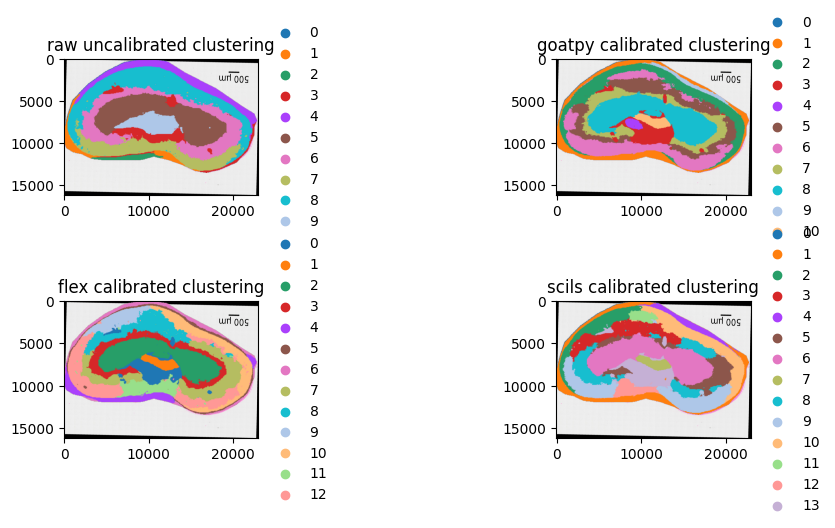

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(10, 5))

raw_aligned.pl.render_images("he_image") \
       .pl.render_shapes("pixels", color="Leiden")\
       .pl.show("aligned", ax=axes[0,0], title="raw uncalibrated clustering")

gp_aligned.pl.render_images("he_image") \
       .pl.render_shapes("pixels", color="Leiden") \
       .pl.show("aligned", ax=axes[0,1], title="goatpy calibrated clustering")

flex_aligned.pl.render_images("he_image") \
       .pl.render_shapes("pixels", color="Leiden") \
       .pl.show("aligned", ax=axes[1,0], title="flex calibrated clustering")

scils_aligned.pl.render_images("he_image") \
       .pl.render_shapes("pixels", color="Leiden") \
       .pl.show("aligned", ax=axes[1,1], title="scils calibrated clustering")

plt.tight_layout()
plt.show()

In [17]:
# save objects to zarr for later use
raw_aligned.write("./Documents/kidney/goatpy_objects/kidney_raw_aligned.zarr")
gp_aligned.write("./Documents/kidney/goatpy_objects/kidney_gp_aligned.zarr")
flex_aligned.write("./Documents/kidney/goatpy_objects/kidney_flex_aligned.zarr")
scils_aligned.write("./Documents/kidney/goatpy_objects/kidney_scils_aligned.zarr")

INFO     The Zarr backing store has been changed from None the new file path:                                      
         ~/Documents/Griffith/test_data/kidney/kidney_raw_aligned.zarr                                             
INFO     The Zarr backing store has been changed from None the new file path:                                      
         ~/Documents/Griffith/test_data/kidney/kidney_gp_aligned.zarr                                              
INFO     The Zarr backing store has been changed from None the new file path:                                      
         ~/Documents/Griffith/test_data/kidney/kidney_flex_aligned.zarr                                            
INFO     The Zarr backing store has been changed from None the new file path:                                      
         ~/Documents/Griffith/test_data/kidney/kidney_scils_aligned.zarr                                           
